In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))

from src.main import train
from src.data import DataStream

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import torch



2026/10/12 17:54:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/jjonkhans/Code/IDBD-optimizer/.venv/lib64/python3.14/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [13]:
experiment_name = "input_dim_step_cnt"


In [ ]:
mlflow.set_experiment(experiment_name)
seed = 1234
tolerance_intervall = 1e-3
stop_condition = lambda step, name, values: (
    values["distractor_weight_rms"] < tolerance_intervall and step > 1000
)

initial_lr = 0.01
meta_lr = 0.01
batch_size = 128
max_iterations = 2**16
# At least one useful feature and one distractor are needed for the RMS.
input_dims = [2**x for x in range(1, 10)]
results = []

with mlflow.start_run(run_name="Steps to stop condition by input dimension"):
    mlflow.log_params({
        "seed": seed,
        "tolerance": tolerance_intervall,
        "initial_lr": initial_lr,
        "meta_lr": meta_lr,
        "batch_size": batch_size,
        "max_iterations": max_iterations,
        "input_dims": input_dims,
    })

    for input_dim in input_dims:
        print(input_dim)
        with mlflow.start_run(run_name=f"input_dim={input_dim}", nested=True):
            torch.manual_seed(seed)
            mlflow.log_param("input_dim", input_dim)
            models, optimizers, history, train_metrics, predictions = train(
                DataStream(input_dim=input_dim, seed=seed),
                iterations=max_iterations, batch_size=batch_size,
                meta_lr=meta_lr, initial_lr=initial_lr,
                stop_condition=stop_condition,
                zeros=True
            )

            

            step_count = {
                name: train_metrics.loc[name, "steps_to_target"]
                for name in models
            }
            for name, steps in step_count.items():
                reached = steps is not None
                results.append({
                    "input_dim": input_dim,
                    "model": name,
                    "steps_to_target": steps,
                    "target_reached": reached,
                })
                mlflow.log_metric(f"{name}.target_reached", int(reached))
                if reached:
                    mlflow.log_metric(f"{name}.steps_to_target", int(steps))

            print("distractor_weight_rms", history[["distractor_weight_rms", "distractor_lr_mean"]])

mlflow.end_run()

Training 5%: 405376 examples, IDBD loss=2.2842, SGD loss=2.2843
distractor_weight_rms 0       0.000087
1       0.000087
2       0.000087
3       0.000087
4       0.000123
          ...   
6329    0.001333
6330    0.001330
6331    0.001333
6332    0.000854
6333    0.000857
Name: distractor_weight_rms, Length: 6334, dtype: float64
Training 10%: 838912 examples, IDBD loss=3.1224, SGD loss=3.1229
Training 20%: 1677824 examples, IDBD loss=2.6815, SGD loss=2.6824
Training 30%: 2516608 examples, IDBD loss=2.5250, SGD loss=2.5250
Training 40%: 3355520 examples, IDBD loss=3.0537, SGD loss=3.0537
Training 50%: 4194304 examples, IDBD loss=2.0874, SGD loss=2.0874
Training 60%: 5033216 examples, IDBD loss=2.4584, SGD loss=2.4584
Training 70%: 5872128 examples, IDBD loss=2.8967, SGD loss=2.8967
Training 80%: 6710912 examples, IDBD loss=2.3765, SGD loss=2.3765
Training 88%: 7390976 examples, IDBD loss=2.1598, SGD loss=2.1592
distractor_weight_rms 0         0.000143
1         0.000143
2         0.0001

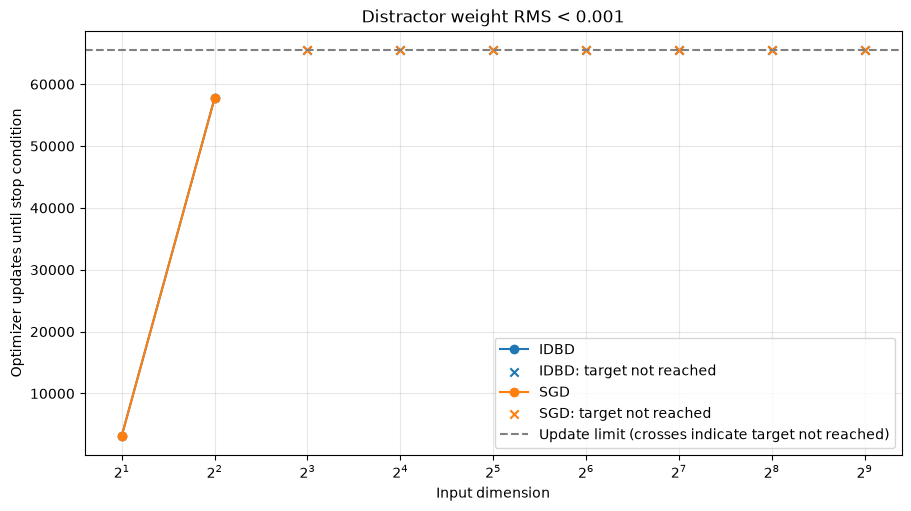

In [8]:
%matplotlib inline

table = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for name, rows in table.groupby("model", sort=False):
    line, = ax.plot(rows["input_dim"], rows["steps_to_target"],
                    marker="o", label=name)
    not_reached = rows[~rows["target_reached"]]
    if not not_reached.empty:
        ax.scatter(not_reached["input_dim"],
                    [max_iterations] * len(not_reached),
                    marker="x", color=line.get_color(),
                    label=f"{name}: target not reached")

ax.set_xscale("log", base=2)
ax.set_xlabel("Input dimension")
ax.set_ylabel("Optimizer updates until stop condition")
ax.set_title(f"Distractor weight RMS < {tolerance_intervall:g}")
ax.axhline(max_iterations, color="gray", linestyle="--",
            label="Update limit (crosses indicate target not reached)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
try:
    mlflow.log_figure(fig, "plots/steps_to_target.png")
finally:
    plt.close(fig)
mlflow.log_text(table.to_csv(index=False), "data/steps_to_target.csv")



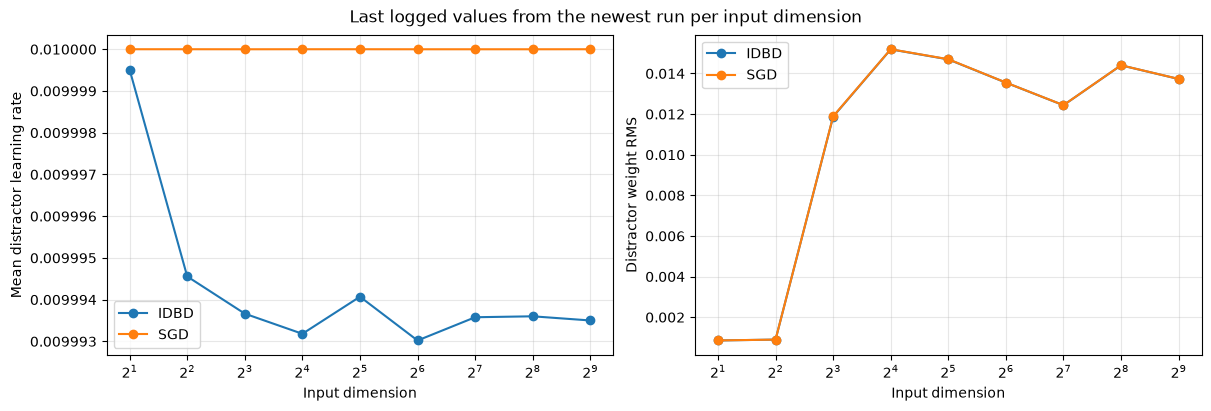

In [44]:
%matplotlib inline

# metrics.* contains the latest logged value for each run.
experiment = mlflow.get_experiment_by_name(experiment_name)
if experiment is None:
    raise ValueError(f"Experiment {experiment_name!r} not found")

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"],
)
# Only the dimension-specific child runs have params.input_dim.
if "params.input_dim" not in runs_df.columns:
    raise ValueError("No runs with an input_dim parameter found")
latest = (
    runs_df.dropna(subset=["params.input_dim"])
    .drop_duplicates(subset=["params.input_dim"], keep="first")
    .copy()
)
latest["input_dim"] = pd.to_numeric(latest["params.input_dim"])
latest = latest.sort_values("input_dim")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for model in ("IDBD","SGD"):
    axes[0].plot(
        latest["input_dim"], latest[f"metrics.train.{model}.distractor_lr_mean"],
        marker="o", label=model,
    )
    axes[1].plot(
        latest["input_dim"], latest[f"metrics.train.{model}.distractor_weight_rms"],
        marker="o", label=model,
    )

axes[0].set_ylabel("Mean distractor learning rate")
axes[1].set_ylabel("Distractor weight RMS")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Input dimension")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle("Last logged values from the newest run per input dimension")
plt.show()
plt.close(fig)
